# 01 · Data audit and preparation (Phase 0)
Goal: turn the two raw CSVs into a tidy **counts matrix** (samples × taxa) and a tidy **metadata table**,
documenting every decision. Raw files in `data/raw/` are never modified.

Questions answered here: where does the real table end? what are the numbers (counts / fractions / percent)?
why do column sums look wrong? how much is missing? how sensitive is the result to the taxon filter?

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from src.config import SEED, RAW, PROCESSED, FIGURES, READS
from src.parse import read_taxonomy, to_counts, aggregate, resolved
from src.clean_env import clean_env
from src.plotstyle import set_style, PALETTE
set_style()
rng = np.random.default_rng(SEED)
PROCESSED.mkdir(exist_ok=True, parents=True); FIGURES.mkdir(exist_ok=True, parents=True)
print("seed", SEED)

Matplotlib is building the font cache; this may take a moment.


seed 20261030


## 1. Parse `taxonomy.csv`: find the real table, decode the numbers

In [2]:
frac, tax, junk = read_taxonomy(RAW / "taxonomy.csv")
print(f"real table: {frac.shape[0]} taxa x {frac.shape[1]} samples (ends at file line {junk['table_end_line']})")
print(f"rows after the table: {junk['n_rows_after_table']}, of which non-blank: {len(junk['nonblank_rows'])}")
for r in junk["nonblank_rows"]:
    cells = [c for c in r if c.strip()]
    print(f"  {len(cells):>3} non-empty cells, first: {cells[:3]}")

real table: 649 taxa x 273 samples (ends at file line 650)
rows after the table: 10, of which non-blank: 5
  273 non-empty cells, first: ['6', '22', '103']
  279 non-empty cells, first: ['Taxon', 'Phylum', 'Class']
  272 non-empty cells, first: ['f__Enterobacteriaceae Other', 'f__Staphylococcaceae Other', 'f__Alicyclobacillaceae g__Alicyclobacillus']
   18 non-empty cells, first: ['0,401', '0,997', '0,121']
    1 non-empty cells, first: ['1304, 1306, 1337, 1364, 1428, 1434, YWL 1015']


The junk block is, in order: an integer row, a repeated header, a row of taxon names, a sparse row of decimals,
and a stray note. Next: what is the integer row? Test the hypothesis that it is the **observed richness** per sample.

In [3]:
rich_row = next(r for r in junk["nonblank_rows"] if r[0] == "" and r[7].strip().isdigit())
rich_junk = pd.Series([int(x) for x in rich_row[7:]], index=frac.columns)
rich_obs = (frac > 0).sum()
print("integer row == number of taxa with >0 abundance:", bool((rich_junk == rich_obs).all()), f"({(rich_junk==rich_obs).sum()}/{len(rich_obs)})")
print("column sums of the 649 real rows: median %.3f, min %.3f, max %.3f" % (frac.sum().median(), frac.sum().min(), frac.sum().max()))
print("if the richness row is included in the sum: median %.1f -> this is the 'median ~31' in the brief" % (frac.sum() + rich_junk).median())

integer row == number of taxa with >0 abundance: True (273/273)
column sums of the 649 real rows: median 1.000, min 0.282, max 1.000
if the richness row is included in the sum: median 31.0 -> this is the 'median ~31' in the brief


**Finding 1.** The integer row is the per-sample richness. Summing it with the abundances gave the odd "median ≈ 31";
over the real 649 rows the median column sum is 1.0, so the values are **fractions**.

**Finding 2.** Are the fractions exact multiples of 1/1000? If yes, the data are *rarefied counts* (1000 reads/sample, matching `Reads = 1000`)
and I can recover integer counts, which is what multinomial-type models need.

In [4]:
counts = to_counts(frac)    # asserts value*1000 is an integer for every cell
print("every cell is k/1000: OK ->", counts.shape, "integer count matrix")
smallest = frac.values[frac.values > 0].min()
print("smallest non-zero value:", smallest, "= 1/%d" % round(1/smallest))
print("sparsity (share of zeros): %.3f" % (counts.values == 0).mean())

every cell is k/1000: OK -> (649, 273) integer count matrix
smallest non-zero value: 0.001 = 1/1000
sparsity (share of zeros): 0.934


**Finding 3 – missing mass.** Some samples sum to less than 1000 reads in the table. Decision (Q1 default): keep exact counts and add an
explicit **`Unassigned`** category = 1000 − sum, so each sample is a full multinomial of 1000 reads. Sensitivity later: drop samples with < 80 % assigned.

samples with assigned reads < 1000: 134 of 273
samples with < 800 assigned: 7 | min: 282 (sample 1306)


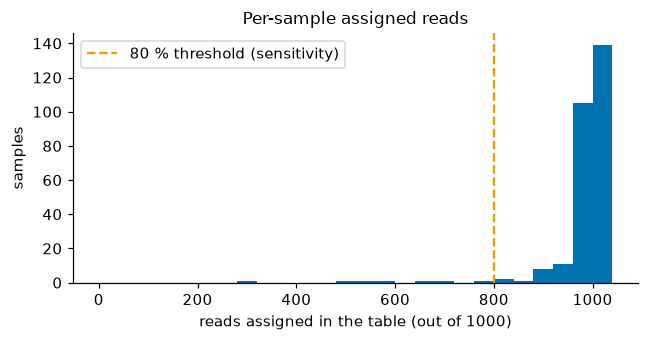

In [5]:
assigned = counts.sum()
print("samples with assigned reads < 1000:", (assigned < READS).sum(), "of", len(assigned))
print("samples with < 800 assigned:", (assigned < 0.8*READS).sum(), "| min:", assigned.min(), f"(sample {assigned.idxmin()})")
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(assigned, bins=np.arange(0, 1041, 40), color=PALETTE[0])
ax.axvline(0.8*READS, color=PALETTE[1], ls="--", label="80 % threshold (sensitivity)")
ax.set(xlabel="reads assigned in the table (out of 1000)", ylabel="samples", title="Per-sample assigned reads"); ax.legend()
fig.tight_layout(); fig.savefig(FIGURES / "audit_assigned_reads.png"); plt.show()

## 2. Clean `environment.csv` and report missingness

In [6]:
env, log, miss_raw = clean_env(RAW / "environment.csv")
assert set(env.index) == set(counts.columns), "IDs differ between files"
print("IDs match:", len(env), "of", counts.shape[1])
env.head()

IDs match: 273 of 273


,Gender,Age,Wash_Freq,Wash_Group,Navel,Ethnicity,In_NC
ID,,,,,,,
1153,Female,18.0,NaN,NaN,Innie,non-Hispanic White,1.0
1161,Male,28.0,NaN,NaN,Innie,non-Hispanic White,1.0
1169,Male,7.0,NaN,NaN,NaN,Other,0.0
979,Female,35.0,NaN,NaN,NaN,NaN,1.0
1113,Female,8.0,NaN,NaN,Innie,Other,1.0


In [7]:
miss_clean = env.isna().mean().rename("missing share (cleaned columns)")
print(pd.concat([miss_raw.rename("missing share (RAW columns)")], axis=1).sort_values(by="missing share (RAW columns)", ascending=False).round(3).to_string())
print()
print(miss_clean.round(3).to_string())

                     missing share (RAW columns)
Country ages 13-19                         0.927
Zipcode ages 13-19                         0.927
Country til age 12                         0.923
ZIP code til age 12                        0.923
Current ZIPcode                            0.747
Wash_Freq                                  0.425
Wash_Range                                 0.425
Innie_or_outie                             0.132
Ethnicity_Category                         0.125
Ethnicity_Quest                            0.125
Current City                               0.106
Age                                        0.099
Age_Range                                  0.099
Current State                              0.059
Gender                                     0.029
Reads                                      0.000

Gender        0.029
Age           0.099
Wash_Freq     0.425
Wash_Group    0.425
Navel         0.132
Ethnicity     0.125
In_NC         0.059


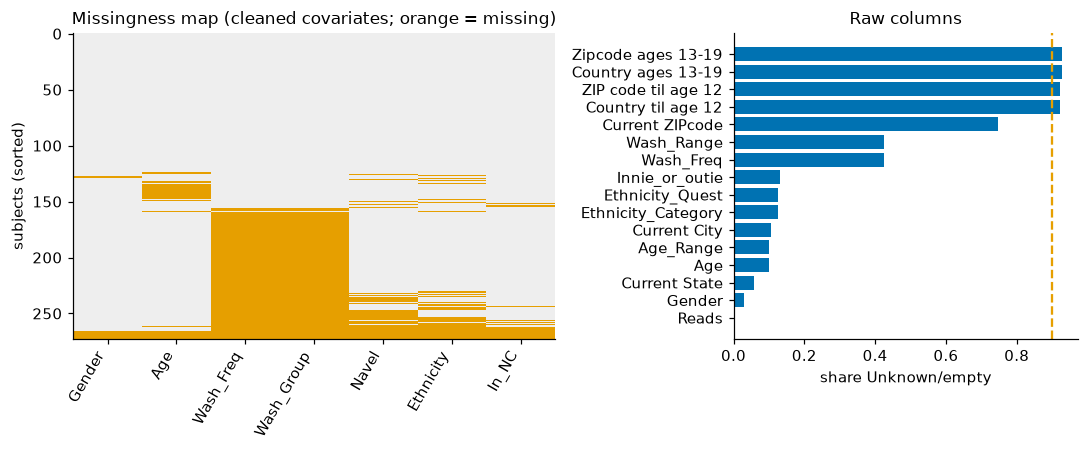

complete cases on (Age, Gender, Wash_Freq, Navel): 132


In [8]:
# missingness map: rows = subjects (sorted by number of missing fields), columns = kept covariates
M = env.isna().astype(int)
order = M.sum(axis=1).sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
axes[0].imshow(M.loc[order].values, aspect="auto", cmap=matplotlib.colors.ListedColormap(["#EEEEEE", PALETTE[1]]), interpolation="nearest")
axes[0].set_xticks(range(M.shape[1])); axes[0].set_xticklabels(M.columns, rotation=60, ha="right")
axes[0].set(ylabel="subjects (sorted)", title="Missingness map (cleaned covariates; orange = missing)")
mr = miss_raw.sort_values()
axes[1].barh(mr.index, mr.values, color=PALETTE[0]); axes[1].set(xlabel="share Unknown/empty", title="Raw columns")
axes[1].axvline(0.9, color=PALETTE[1], ls="--"); fig.tight_layout()
fig.savefig(FIGURES / "audit_missingness.png"); plt.show()
print("complete cases on (Age, Gender, Wash_Freq, Navel):", env[["Age","Gender","Wash_Freq","Navel"]].dropna().shape[0])

### Decision table (decision, reason, rows affected)

In [9]:
decisions = log.table()
decisions.to_csv(PROCESSED / "decision_table_env.csv", index=False)
decisions

,decision,reason,rows_affected
0,strip leading/trailing whitespace in all columns,"e.g. 'Innie ' vs 'Innie', 'NC ' vs 'NC'",10
1,"'Unknown'/empty -> NaN, no imputation",missing stays missing; models use complete cas...,1657
2,"Innie_or_outie: case-fold to {Innie, Outie}",'innie'/'Innie '/'Innie' are one label,72
3,"Wash_Freq: decimal comma -> point, to float","'3,5' -> 3.5",7
4,Wash_Range inconsistent with Wash_Freq: keep W...,e.g. range 'none' with freq 0.25; 'None'/'none...,2
5,Ethnicity: Latino->Hispanic; Black/Asian/India...,groups with n<10 cannot be estimated; Ethnicit...,55
6,Geography: keep only In_NC (is current state N...,ZIPs are >=70% missing and partly corrupt ('11...,257
7,Drop columns with >= 90% missing: ['Country ti...,no information to model,273
8,Drop Reads,constant 1000 for all subjects (rarefied),273


## 3. Aggregate taxa
Rank values `Other` and an empty `x__` both mean *unresolved at this rank*. Each row gets the label of its **deepest resolved rank**
(`Family;Genus` when the genus is known). Rows sharing a label are summed. This keeps family-level information instead of dumping
the 204 rows with no genus into one bucket (Q3 default).

In [10]:
agg, lab = aggregate(counts, tax)
print("rows before:", counts.shape[0], "-> labels after:", agg.shape[0])
print("duplicate Family_Genus keys in raw file:", tax["Family_Genus"].duplicated().sum())
print("share of reads with genus resolved: %.3f" % (counts[lab["genus_resolved"].values].values.sum() / counts.values.sum()))
agg.loc["Unassigned"] = READS - agg.sum()          # Q1 default: explicit missing-mass category
assert (agg.sum() == READS).all() and (agg.values >= 0).all()
X = agg.T                                           # samples x taxa
X.index.name = "ID"

rows before: 649 -> labels after: 585
duplicate Family_Genus keys in raw file: 120
share of reads with genus resolved: 0.639


## 4. Filter: prevalence threshold and its sensitivity
Rule fixed **before** modelling: keep taxa present (≥1 read) in at least `PREV_MIN` of samples; collapse everything else into `Other`.
`Unassigned` is always kept as its own category. The table shows how the choice changes the number of taxa and the reads moved into `Other`.

In [11]:
prev = (X > 0).mean()
rows = []
for p in [0.02, 0.05, 0.10, 0.20, 0.30]:
    keep = prev[(prev >= p) & (prev.index != "Unassigned")].index
    other = READS - X[keep].sum(axis=1) - X["Unassigned"]
    rows.append({"min prevalence": p, "taxa kept": len(keep), "median reads in Other": other.median(),
                 "mean share in Other": other.mean()/READS, "zeros in kept table": (X[keep] == 0).values.mean()})
sens = pd.DataFrame(rows); sens.to_csv(PROCESSED / "filter_sensitivity.csv", index=False)
sens.round(3)

,min prevalence,taxa kept,median reads in Other,mean share in Other,zeros in kept table
0,0.02,269,1.0,0.004,0.853
1,0.05,177,3.0,0.012,0.794
2,0.10,112,8.0,0.033,0.714
3,0.20,66,25.0,0.061,0.613
4,0.30,36,85.0,0.135,0.497


In [12]:
PREV_MIN = 0.10   # simplification: one fixed threshold; sensitivity table above shows the trade-off
keep = prev[(prev >= PREV_MIN) & (prev.index != "Unassigned")].sort_values(ascending=False).index
Xf = X[keep].copy()
Xf["Other"] = READS - Xf.sum(axis=1) - X["Unassigned"]
Xf["Unassigned"] = X["Unassigned"]
assert (Xf.sum(axis=1) == READS).all() and (Xf.values >= 0).all()
print(f"kept {len(keep)} taxa + Other + Unassigned = {Xf.shape[1]} categories; zeros: {(Xf.values==0).mean():.3f}")
Xf.iloc[:, :12].head()

kept 112 taxa + Other + Unassigned = 114 categories; zeros: 0.707


,Corynebacteriaceae;Corynebacterium,Staphylococcaceae (unresolved below family),Clostridiaceae;Anaerococcus,Bacteria (unresolved below kingdom),Alicyclobacillaceae;Alicyclobacillus,Prevotellaceae;Prevotella,Clostridiaceae;Finegoldia,Streptococcaceae;Streptococcus,Clostridiaceae;Peptoniphilus,Porphyromonadaceae;Porphyromonas,Actinomycetales (unresolved below order),Moraxellaceae;Acinetobacter
ID,,,,,,,,,,,,
1153,14,7,0,1,0,0,0,0,0,0,0,0
1161,211,729,20,0,3,0,2,3,0,0,0,0
1169,8,27,1,3,121,3,1,17,1,2,0,29
979,9,57,37,10,0,3,0,0,32,392,9,0
1113,5,32,1,0,21,1,0,23,0,0,0,9


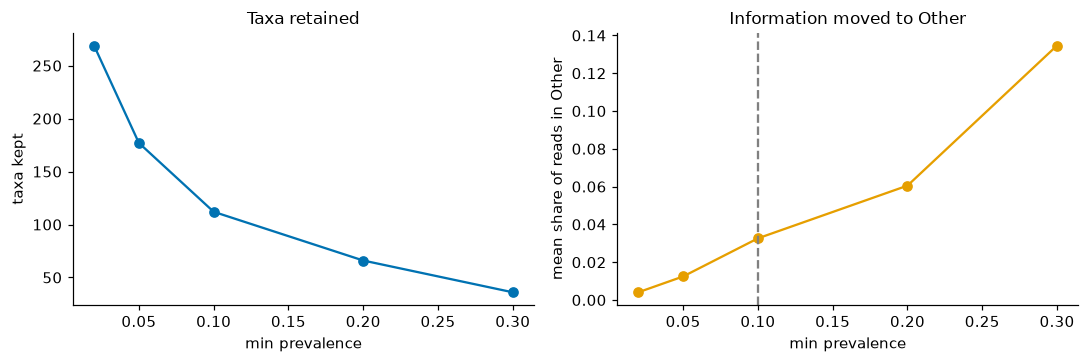

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(sens["min prevalence"], sens["taxa kept"], "o-", color=PALETTE[0]); ax[0].set(xlabel="min prevalence", ylabel="taxa kept", title="Taxa retained")
ax[1].plot(sens["min prevalence"], sens["mean share in Other"], "o-", color=PALETTE[1]); ax[1].axvline(PREV_MIN, ls="--", color="grey")
ax[1].set(xlabel="min prevalence", ylabel="mean share of reads in Other", title="Information moved to Other")
fig.tight_layout(); fig.savefig(FIGURES / "audit_filter_sensitivity.png"); plt.show()

## 5. Save tidy outputs

In [14]:
meta = env.loc[Xf.index].copy()
meta["assigned_reads"] = assigned.loc[Xf.index]
X.to_csv(PROCESSED / "counts_all_labels.csv")        # every label + Unassigned (no prevalence filter)
Xf.to_csv(PROCESSED / "counts_filtered.csv")         # default analysis matrix
meta.to_csv(PROCESSED / "metadata.csv")
tax_map = pd.DataFrame({"raw_row": range(len(lab)), "label": lab["label"]}); tax_map.to_csv(PROCESSED / "taxon_label_map.csv", index=False)
print({p.name: p.stat().st_size for p in PROCESSED.glob("*.csv")})

{'taxon_label_map.csv': 25025, 'decision_table_env.csv': 1152, 'counts_filtered.csv': 71046, 'filter_sensitivity.csv': 344, 'counts_all_labels.csv': 344708, 'metadata.csv': 14861}
